Task 3: Historical temperature data

In [16]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import json
import os
from dotenv import load_dotenv

load_dotenv()
client_id = os.getenv("FROST_CLIENT_ID")
client_secret = os.getenv("FROST_CLIENT_SECRET")


In [20]:
def get_weather_data(
    station_id: str,
    elements: str,
    start_date: str,
    end_date: str,
) -> pd.DataFrame:
    """
    Fetch selected weather observations from Frost API.

    Args:
        station_id: Frost station ID, e.g. "SN18700".
        elements: Measurement element ID, e.g. "air_temperature".
        start_date: Start date in YYYY-MM-DD format.
        end_date: End date in YYYY-MM-DD format.

    Returns:
        A DataFrame containing the requested observations.

    Raises:
        ValueError: If the Frost Client ID is missing.
        requests.HTTPError: If the API request fails.
        requests.RequestException: If a connection error occurs.
    """
    if not client_id:
        raise ValueError("FROST_CLIENT_ID was not found.")

    url = "https://frost.met.no/observations/v0.jsonld"

    params = {
        "sources": station_id,
        "elements": elements,
        "referencetime": f"{start_date}/{end_date}",
    }

    response = requests.get(
        url,
        auth=(client_id, ""),
        params=params,
        timeout=30,
    )
    response.raise_for_status()

    data = response.json()["data"]

    if not data:
        return pd.DataFrame()

    df = pd.json_normalize(
        data,
        record_path="observations",
        meta=["sourceId", "referenceTime"],
    )

    return df


In [34]:
df = get_weather_data(
    station_id="SN17850",
    elements="mean(air_temperature P1D)",
    start_date="1925-01-01",
    end_date="1925-12-31",
)

display(df.head())

,elementId,value,unit,timeOffset,timeResolution,timeSeriesId,performanceCategory,exposureCategory,qualityCode,level.levelType,level.unit,level.value,sourceId,referenceTime
0,mean(air_temperature P1D),1.3,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-01T00:00:00.000Z
1,mean(air_temperature P1D),4.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-02T00:00:00.000Z
2,mean(air_temperature P1D),2.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-03T00:00:00.000Z
3,mean(air_temperature P1D),0.1,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-04T00:00:00.000Z
4,mean(air_temperature P1D),-2.2,degC,PT0H,P1D,0,C,1,2,height_above_ground,m,2,SN17850:0,1925-01-05T00:00:00.000Z


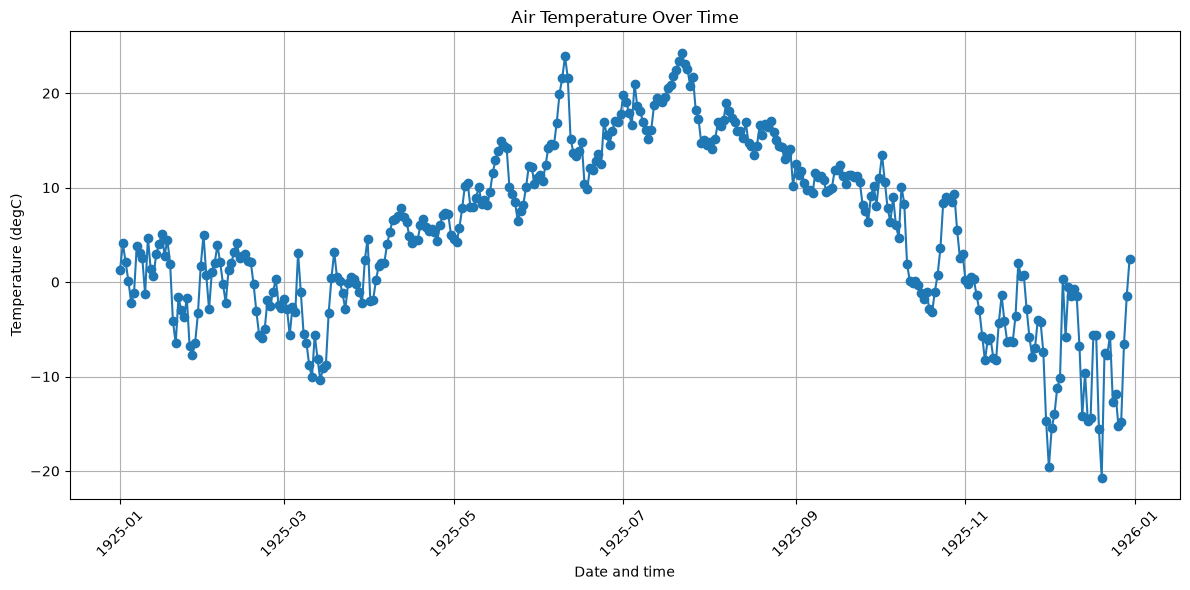

,Statistic,Temperature (°C)
0,Mean,5.31
1,Median,5.30
2,Min,-20.70
3,Max,24.30


In [36]:
# Check that data is available
if df.empty:
    print("No weather data found for the selected period.")

else:
    # Convert observation times to datetime
    df["referenceTime"] = pd.to_datetime(df["referenceTime"])

    # Sort observations by time
    df = df.sort_values("referenceTime")

    # Create the plot
    plt.figure(figsize=(12, 6))
    plt.plot(
        df["referenceTime"],
        df["value"],
        marker="o",
        linestyle="-",
    )

    # Add labels and title
    plt.xlabel("Date and time")
    plt.ylabel(f"Temperature ({df['unit'].iloc[0]})")
    plt.title("Air Temperature Over Time")

    # Improve layout
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()

    # Display the plot
    plt.show()


# Calculate summary statistics for the year
summary_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max"],
    "Temperature (°C)": [
        df["value"].mean(),
        df["value"].median(),
        df["value"].min(),
        df["value"].max(),
    ],
})

# Round values to two decimal places
summary_table["Temperature (°C)"] = (
    summary_table["Temperature (°C)"].round(2)
)

# Display summary table
display(summary_table)


Oppgaven oppdateres etter oppgave 1 er ferdigstilt....
1. mean.temp fra 2025 legges inn i plot sammen med mean.temp for 1925
2. oppsummeringstabell oppdateres med tall fra 2025. legg til kolonnenavn "2025" og "1925"
3. Gjerne sammenligne innhentningskoder mellom task 1 og task 3. trenger bare bruke en gjennom hele oppgaven.
4. sammenlign også oppsett av oppsummeringstabell, slik at disse blir like gjennom oppgaven.
5. trenger ikke å importere flere plasser i oppgaven. foreslår å sammle alle importeringer til en code-rute. får da ogsa en samlet oversikt over import.